<font face="Times New Roman" size=5>
<div dir=rtl align="center">

<br>
<img src="https://logoyar.com/content/wp-content/uploads/2021/04/sharif-university-logo.png" alt="University Logo" width="150" height="150">
<br>
<font face="Times New Roman" size=4 align=center>
Sharif University of Technology - Department of Electrical Engineering
</font>
<br>
<font color="#008080" size=6>
Introduction to Machine Learning
</font>

<hr/>
<font color="#80a080" size=5>
Assignment 3: Regression  
<br>
</font>
<font size=5>
Instructor: Dr. S. Amini
<br>
</font>
<font size=4>
Spring 2026
<br>
</font>
<hr>
</div></font>

> - Full Name: **[Saba Atashfaraz]**
> - Student ID: **[[student ID omitted]]**

<hr>
<hr>

# Problem 1: Linear Regression

### Importing needed libraries

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression
%matplotlib inline

### Loading our housing dataset
We will load our data on house sales in King County to predict house prices using simple (one input) linear regression. We want to be able to predict Y which is our price variable.

### Data Analysis
We can perform basic data analysis using `info`, `describe`, and `head`.

In [7]:
dataset = pd.read_csv('kc_house_data.csv')
Y = dataset[['price']]
X = dataset.drop(['price', 'id', 'date'],  axis=1)

using pandas `.info()` we see we have 18 columns and 21613 records. Pretty much all the features given are already in numeric format.

In [8]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   bedrooms       21613 non-null  int64  
 1   bathrooms      21613 non-null  float64
 2   sqft_living    21613 non-null  int64  
 3   sqft_lot       21613 non-null  int64  
 4   floors         21613 non-null  float64
 5   waterfront     21613 non-null  int64  
 6   view           21613 non-null  int64  
 7   condition      21613 non-null  int64  
 8   grade          21613 non-null  int64  
 9   sqft_above     21613 non-null  int64  
 10  sqft_basement  21613 non-null  int64  
 11  yr_built       21613 non-null  int64  
 12  yr_renovated   21613 non-null  int64  
 13  zipcode        21613 non-null  int64  
 14  lat            21613 non-null  float64
 15  long           21613 non-null  float64
 16  sqft_living15  21613 non-null  int64  
 17  sqft_lot15     21613 non-null  int64  
dtypes: flo

In [9]:
columns = X.columns
columns

Index(['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [10]:
#show first 5 records
X.head()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


`.describe` generates descriptive statistics that summarize the central tendency, dispersion and shape of a dataset's distribution, excluding NaN values.

In [11]:
X.describe()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


We can alse compute correlation between variables and our predictor variable.

In [12]:
dataset = dataset.drop(['id', 'date'], axis=1)
dataset.corr(method='pearson')

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
price,1.000000,0.308350,0.525138,0.702035,0.089661,0.256794,0.266369,0.397293,0.036362,0.667434,0.605567,0.323816,0.054012,0.126434,-0.053203,0.307003,0.021626,0.585379,0.082447
bedrooms,0.308350,1.000000,0.515884,0.576671,0.031703,0.175429,-0.006582,0.079532,0.028472,0.356967,0.477600,0.303093,0.154178,0.018841,-0.152668,-0.008931,0.129473,0.391638,0.029244
bathrooms,0.525138,0.515884,1.000000,0.754665,0.087740,0.500653,0.063744,0.187737,-0.124982,0.664983,0.685342,0.283770,0.506019,0.050739,-0.203866,0.024573,0.223042,0.568634,0.087175
sqft_living,0.702035,0.576671,0.754665,1.000000,0.172826,0.353949,0.103818,0.284611,-0.058753,0.762704,0.876597,0.435043,0.318049,0.055363,-0.199430,0.052529,0.240223,0.756420,0.183286
sqft_lot,0.089661,0.031703,0.087740,0.172826,1.000000,-0.005201,0.021604,0.074710,-0.008958,0.113621,0.183512,0.015286,0.053080,0.007644,-0.129574,-0.085683,0.229521,0.144608,0.718557
floors,0.256794,0.175429,0.500653,0.353949,-0.005201,1.000000,0.023698,0.029444,-0.263768,0.458183,0.523885,-0.245705,0.489319,0.006338,-0.059121,0.049614,0.125419,0.279885,-0.011269
waterfront,0.266369,-0.006582,0.063744,0.103818,0.021604,0.023698,1.000000,0.401857,0.016653,0.082775,0.072075,0.080588,-0.026161,0.092885,0.030285,-0.014274,-0.041910,0.086463,0.030703
view,0.397293,0.079532,0.187737,0.284611,0.074710,0.029444,0.401857,1.000000,0.045990,0.251321,0.167649,0.276947,-0.053440,0.103917,0.084827,0.006157,-0.078400,0.280439,0.072575
condition,0.036362,0.028472,-0.124982,-0.058753,-0.008958,-0.263768,0.016653,0.045990,1.000000,-0.144674,-0.158214,0.174105,-0.361417,-0.060618,0.003026,-0.014941,-0.106500,-0.092824,-0.003406
grade,0.667434,0.356967,0.664983,0.762704,0.113621,0.458183,0.082775,0.251321,-0.144674,1.000000,0.755923,0.168392,0.446963,0.014414,-0.184862,0.114084,0.198372,0.713202,0.119248


for gaining better insight, we can visualize the table above.

<Axes: >

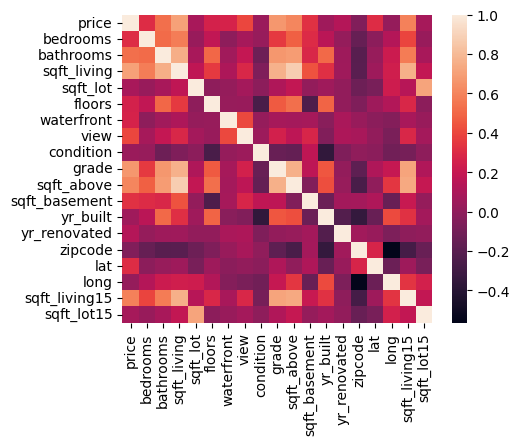

In [13]:
plt.subplots(figsize=(5,4))
sns.heatmap(dataset.corr())

Now that we have gained some insight about our dataset, we can implement linear regression.

<hr>

## 1.1  Simple Linear Regression
We will start with **Simple Linear Regression** since it is easier to understand and visualize before moving to **Multiple Linear Regression**. Though, the concepts overall are similar and the libraries we will be using are actually designed to handle both without distinction. Simple Linear Regression is easier to plot and visualize so we will start with that.

It is **Simple Linear Regression** when we have one dependent variable (feature) and one independent variable. Here we will pick `sqft_living` as our independent variable `X`.

Our goal is to estimate $\hat{y} = x \theta_1 + \theta_0 $, where $ \theta_1 $ is our coefficient and $ \theta_0 $ is our intercept. To estimate $ \hat{y} $ we need to find a function such as $ \hat{y} = h(x) = x \theta_1 + \theta_0 $.

We first start by creating our `x` and `y` variables. Then plotting to gain an intuition on how the data looks like.


In [14]:
x = X[['sqft_living']]
y = Y

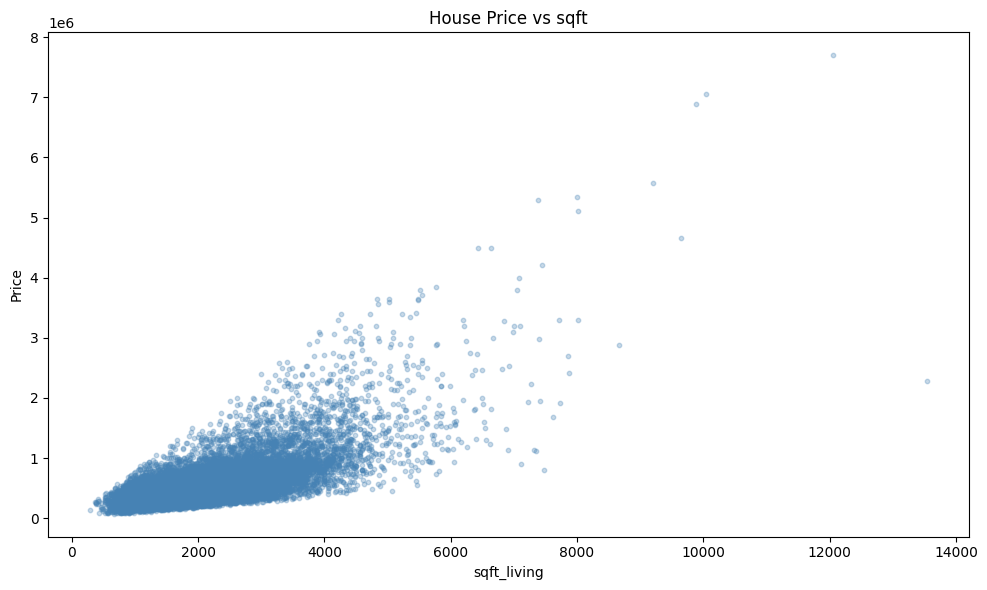

In [15]:
#TODO: plot the data for visualization

plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.3, color='steelblue', s=10)
plt.xlabel('sqft_living')
plt.ylabel('Price')
plt.title('House Price vs sqft')
plt.tight_layout()
plt.show()

###  Gradient Descent Implementation

complete the TODO parts to implement linear regression.

In [16]:
# do not change this cell
x = X[['sqft_living']]
y = Y
xg = x.values.reshape(-1,1)
yg = y.values.reshape(-1,1)
xg = np.concatenate((np.ones(len(x)).reshape(-1,1), x), axis=1)

In [17]:
def computeCost(x, y, theta):
    #TODO
    errors = x @ theta - y
    cost = (1 / (2 * len(y))) * np.sum(errors ** 2)
    return cost

In [18]:
def gradientDescent(x, y, theta, alpha, iterations):
    #TODO
    j_hist = []
    for _ in range(iterations):
        errors = x @ theta - y
        theta = theta - (alpha / len(y)) * x.T.dot(errors)
        j_hist.append(computeCost(x, y, theta))
    return theta, j_hist

In [19]:
#TODO: Normalize your data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
xg_scaled = scaler.fit_transform(xg[:, 1].reshape(-1, 1))        
xg_norm = np.concatenate((np.ones((len(xg_scaled), 1)), xg_scaled), axis=1)

In [20]:
#TODO: train your model on the given dataset. What is the result?

theta_init = np.zeros((2, 1))
alpha      = 0.01
iterations = 1000

theta, cost = gradientDescent(xg_norm, yg, theta_init, alpha, iterations)
print('Theta found by Gradient Descent: slope = {} and intercept {}'.format(theta[1], theta[0]))

Theta found by Gradient Descent: slope = [257719.07230277] and intercept [540064.82548774]


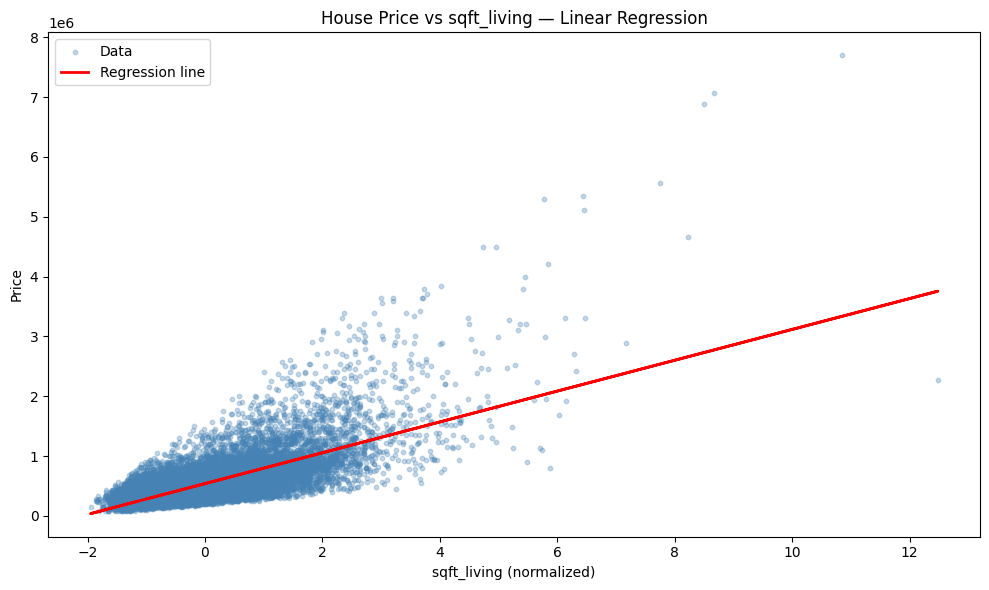

In [21]:
#TODO: plot the data points and the model prediction
predictions = xg_norm.dot(theta)

plt.figure(figsize=(10, 6))
plt.scatter(xg_norm[:, 1], yg, alpha=0.3, s=10, color='steelblue', label='Data')
plt.plot(xg_norm[:, 1], predictions, color='red', linewidth=2, label='Regression line')
plt.xlabel('sqft_living (normalized)')
plt.ylabel('Price')
plt.title('House Price vs sqft_living — Linear Regression')
plt.legend()
plt.tight_layout()
plt.show()


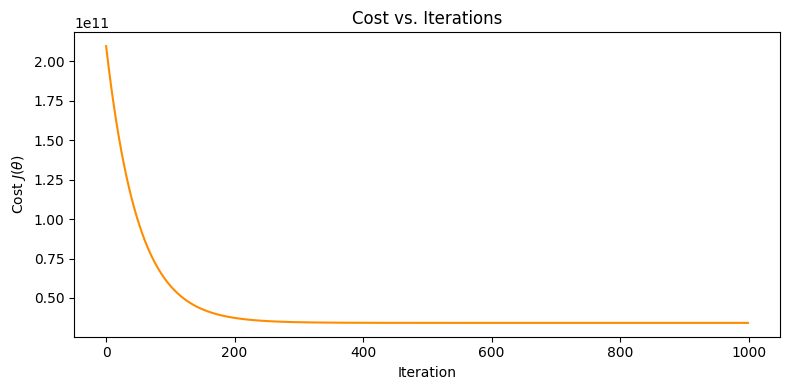

In [22]:
#TODO: visualize how the cost changes
plt.figure(figsize=(8, 4))
plt.plot(range(iterations), cost, color='darkorange')
plt.xlabel('Iteration')
plt.ylabel('Cost $J(\\theta)$')
plt.title('Cost vs. Iterations')
plt.tight_layout()
plt.show()

<hr>

## 1.2 Multiple Linear Regression
Multiple Linear Regression (MLR) is an extension of simple linear regression that models the relationship between two or more explanatory variables (features) and a dependent variable (target). 

Implement Multiple Linear Regression for this dataset.

Final training cost (MLR): 20233457778.74639


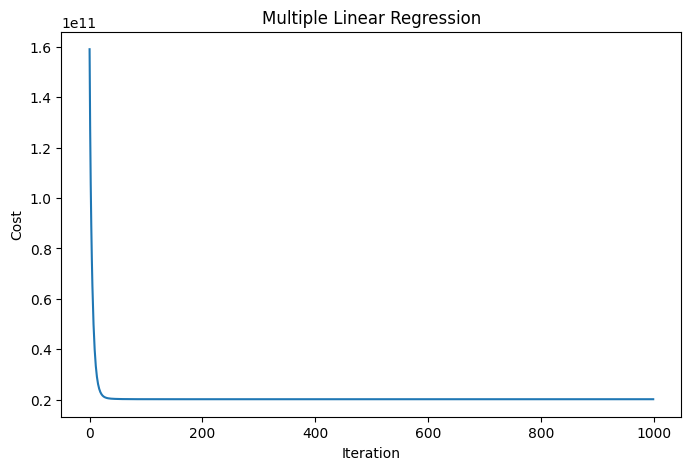

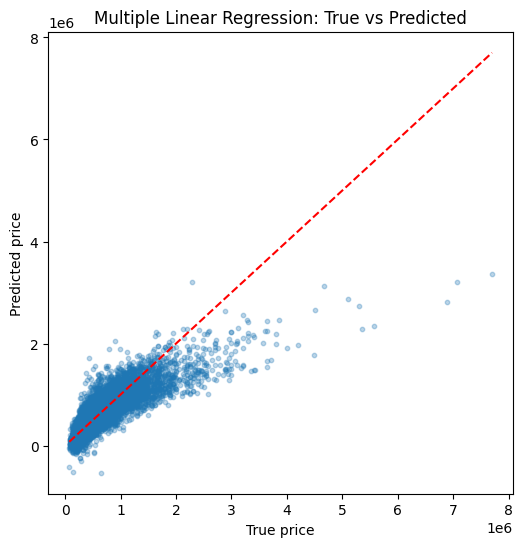

R^2 (Multiple Linear Regression): 0.6997471890109157


In [23]:
#TODO:

X_multi = X.copy()
y_multi = Y.values.reshape(-1, 1)

scaler_multi = StandardScaler()
X_multi_scaled = scaler_multi.fit_transform(X_multi)
xg_multi = np.concatenate((np.ones((X_multi_scaled.shape[0], 1)), X_multi_scaled), axis=1)

theta_multi_init = np.zeros((xg_multi.shape[1], 1))
alpha_multi = 0.1
iterations_multi = 1000

theta_multi, cost_multi = gradientDescent(xg_multi, y_multi, theta_multi_init, alpha_multi, iterations_multi)
print('Final training cost (MLR):', cost_multi[-1])

predictions_multi = xg_multi @ theta_multi

plt.figure(figsize=(8, 5))
plt.plot(cost_multi)
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.title('Multiple Linear Regression')
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(y_multi, predictions_multi, alpha=0.3, s=10)
plt.plot([y_multi.min(), y_multi.max()], [y_multi.min(), y_multi.max()], 'r--')
plt.xlabel('True price')
plt.ylabel('Predicted price')
plt.title('Multiple Linear Regression: True vs Predicted')
plt.show()

ss_res = np.sum((y_multi - predictions_multi) ** 2)
ss_tot = np.sum((y_multi - y_multi.mean()) ** 2)
r2_multi = 1 - ss_res / ss_tot
print('R^2 (Multiple Linear Regression):', r2_multi)


<hr>

## 1.3 Linear Regression with Regularization

In traditional linear regression, we try to find the best-fitting line by minimizing the cost function . However, when dealing with complex data, overfitting can occur, especially when the model is too complex or when there are many features in the data.

To combat overfitting and improve the generalization of the model, regularization techniques are used. Regularization adds a penalty term to the cost function to constrain the model and prevent it from fitting the noise in the training data.

### Types of Regularization

#### 1. Ridge Regression (L2 Regularization):
Ridge regression adds a penalty term to the cost function that is proportional to the square of the coefficients. The goal is to shrink the coefficients toward zero but never exactly zero. This helps to reduce model complexity and prevent overfitting.

**Cost Function**:
$
J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2 + \lambda \sum_{j=1}^{n} \theta_j^2
$

Where:
- $ \lambda $ is the regularization parameter (also called the **ridge penalty**).
- $ \theta_j $ are the model coefficients.
- The term $ \sum_{j=1}^{n} \theta_j^2 $ is the penalty term that controls the size of the coefficients. Larger $ \lambda $ values result in stronger regularization.

---

#### 2. Lasso Regression (L1 Regularization):
Lasso regression adds a penalty to the sum of the absolute values of the coefficients. The cost function is modified to include the sum of the absolute values of the coefficients. Lasso has the unique property that it can drive some of the coefficients exactly to zero, effectively performing feature selection.

**Cost Function**:
$
J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2 + \lambda \sum_{j=1}^{n} |\theta_j|
$

Where:
- $ \lambda $ is the regularization parameter (also called the **lasso penalty**).
- The term $ \sum_{j=1}^{n} |\theta_j| $ is the penalty term that controls the magnitude of the coefficients. Lasso has the unique property that it can drive some coefficients exactly to zero.

In this question, we want to develope a class `linear regression` and add regularization to our model.


Explain **When to Use Ridge Regression and Lasso Regression**.

Both Ridge and Lasso are useful when a model has many correlated or irrelevant features and is at risk of overfitting.

- **Ridge (L2)** is preferable when most or all of the features are believed to contribute at least a little to the output, and you mainly want to shrink large coefficients to reduce variance without removing any feature entirely.

- **Lasso (L1)** is preferable when you suspect that only a subset of the features are actually relevant. Because the L1 penalty can drive coefficients exactly to zero, Lasso performs implicit feature selection and produces a sparse, more interpretable model. It is less stable than Ridge when features are highly correlated (it tends to arbitrarily pick one of a correlated group).

In practice, when sparsity is important we use Lasso; when predictive accuracy with all features retained is the goal (and especially with correlated predictors), we use Ridge.

Also explain **the effect of the regularization parameter**: 

The regularization parameter $\lambda$ controls the trade-off between fitting the training data well and keeping the model coefficients small:

- When $\lambda = 0$, the penalty term vanishes and the model reduces to ordinary least squares: it fits the training data as closely as possible, which can lead to overfitting.
- As $\lambda$ increases, the penalty on the coefficients grows, forcing them to shrink toward zero. This increases bias but reduces variance, which can improve generalization on the test set, up to a point.
- If $\lambda$ becomes too large, the model becomes overly constrained (underfitting): coefficients are pushed too close to zero, the model captures almost none of the signal in the data, and both training and test error increase.

So there is a "sweet spot" for $\lambda$ that minimizes test error. This is exactly why we sweep over a range of $\lambda$ values and choose the one that minimizes validation MSE, instead of arbitrarily increasing or decreasing it.

Complete the code below for the linear regression class.

In [24]:
#TODO: complete this cell
class LinearRegression:
    def __init__(self, lr=0.001, n_iters=1000, penalty = None,lambda_=0.0):
        #TODO
        self.lr = lr
        self.n_iters = n_iters
        self.penalty = penalty   
        self.weights = None
        self.bias = None
        self.lambda_  = lambda_
        self.j_hist = []
    
    def fit(self, X, y):
        #TODO 
        m, n = X.shape
        self.weights = np.zeros(n)
        self.bias    = 0.0
        self.j_hist  = []

        for i in range(self.n_iters):
            #TODO
            # add regularization derevitive terme
            y_pred = X.dot(self.weights) + self.bias
            errors = y_pred - y

            dw = (1 / m) * X.T.dot(errors)
            db = (1 / m) * np.sum(errors)

            if self.penalty == 'l1':
                #TODO
                dw += (self.lambda_ / m) * np.sign(self.weights)
            elif self.penalty == 'l2':
                #TODO
                dw += (self.lambda_ / m) * 2 * self.weights
            
            
            #TODO
            self.weights -= self.lr * dw
            self.bias    -= self.lr * db

            cost = (1 / (2 * m)) * np.sum(errors ** 2)

            if self.penalty == 'l1':
                cost += self.lambda_ * np.sum(np.abs(self.weights))

            elif self.penalty == 'l2':
                cost += self.lambda_ * np.sum(self.weights ** 2)

            self.j_hist.append(cost)
            
    def predict(self, X):
        #TODO
        return X.dot(self.weights) + self.bias

In [25]:
# Do not change this cell
n_samples = 1000
n_features = 10
X, y = make_regression(n_samples=n_samples, n_features=n_features, n_informative=5, noise=10, random_state=42)

Apply train-test split.

In [26]:
#TODO: train-test split
X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

Visualize your data points.

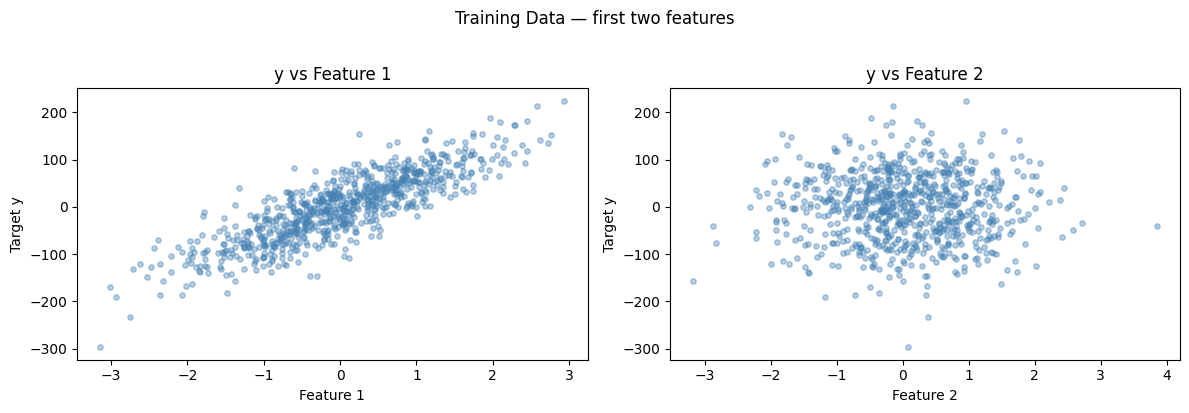

In [27]:
# TODO
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, ax in enumerate(axes):
    ax.scatter(X_fit[:, i], y_fit, alpha=0.4, s=15, color='steelblue')
    ax.set_xlabel(f'Feature {i+1}')
    ax.set_ylabel('Target y')
    ax.set_title(f'y vs Feature {i+1}')

plt.suptitle('Training Data — first two features', y=1.02)
plt.tight_layout()
plt.show()

Train your model and  evaluate your model using MMSE, $R^2$ criterions, how well is your model trained?

In [28]:
def mse(y, predictions):
    #TODO
    return np.mean((np.array(y) - np.array(predictions)) ** 2)

def r2(y, predictions):
    ss_res = np.sum((np.array(y) - np.array(predictions)) ** 2)
    ss_tot = np.sum((np.array(y) - np.mean(predictions)) ** 2)
    return 1 - ss_res / ss_tot


101.13803939898942


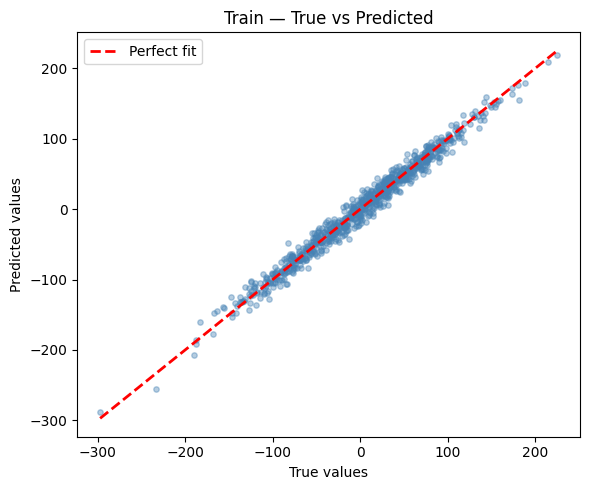

MSE : 101.1380
R²  : 0.9800


In [29]:
#TODO: train your model and make predictions
model = LinearRegression(lr=0.01, n_iters=1000, penalty='l2', lambda_=0.1)
model.fit(X_fit, y_fit)

train_predictions = model.predict(X_fit)


mse(y_fit, train_predictions)
y_pred_train = train_predictions

print(mse(y_fit, y_pred_train))


#TODO: plot the True values and predicted train values
plt.figure(figsize=(6, 5))
plt.scatter(y_fit, y_pred_train, alpha=0.4, s=15, color='steelblue')
plt.plot([y_fit.min(), y_fit.max()], [y_fit.min(), y_fit.max()],'r--', linewidth=2, label='Perfect fit')
plt.xlabel('True values')
plt.ylabel('Predicted values')
plt.title('Train — True vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

#TODO: MMSE and R^2
print(f"MSE : {mse(y_fit, y_pred_train):.4f}")
print(f"R²  : {r2(y_fit, y_pred_train):.4f}")

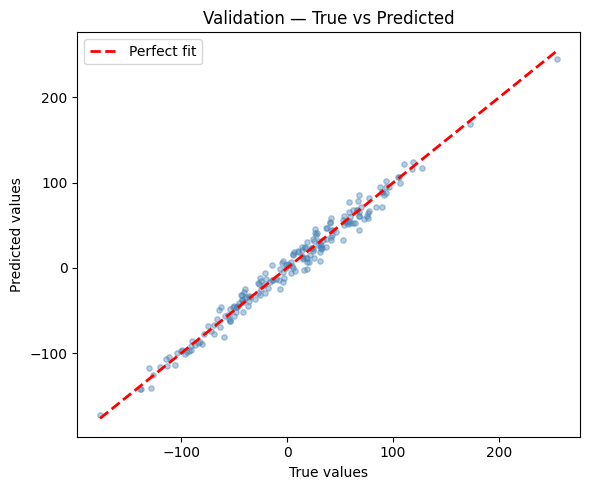

MSE : 77.9137
R²  : 0.9815


In [30]:
#TODO: make predictions using the model. 
#TODO: plot the True values and predicted test values
#TODO: Evaluate your model
y_pred_val = model.predict(X_val)

plt.figure(figsize=(6, 5))
plt.scatter(y_val, y_pred_val, alpha=0.4, s=15, color='steelblue')
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()],'r--', linewidth=2, label='Perfect fit')
plt.xlabel('True values')
plt.ylabel('Predicted values')
plt.title('Validation — True vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

print(f"MSE : {mse(y_val, y_pred_val):.4f}")
print(f"R²  : {r2(y_val, y_pred_val):.4f}")


<hr>

### Ridge Regression:
Train your model using L2 regularization. Then change $\lambda$ and plot the train and test error with respect to $\lambda$. what is the best  $\lambda$?

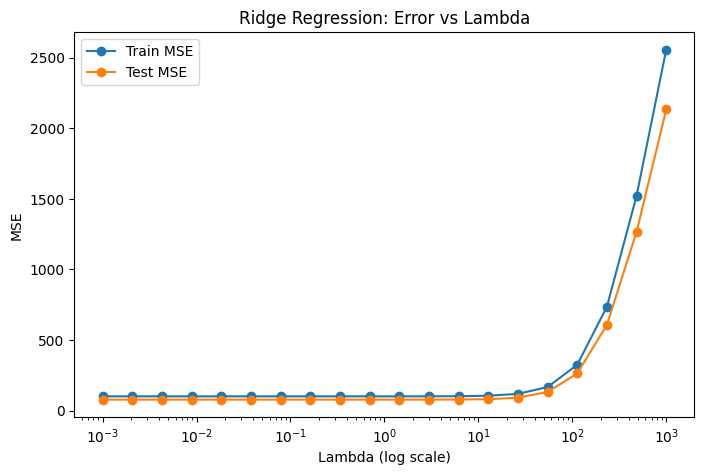

Best lambda for Ridge: 0.6951927961775606
Train MSE at best lambda: 101.15132342371977
Test MSE at best lambda: 77.9021000491039


In [34]:
#TODO: train your model and make predictions
#TODO: plot the True values and predicted train values
#TODO: MMSE and R^2
#TODO: change lammbda and see the differences.

lambdas = np.logspace(-3, 3, 20)
train_errors_ridge = []
test_errors_ridge = []

for lam in lambdas:
    ridge_model = LinearRegression(lr=0.1, n_iters=2000, penalty='l2', lambda_=lam)
    ridge_model.fit(X_fit, y_fit)
    train_pred = ridge_model.predict(X_fit)
    test_pred = ridge_model.predict(X_val)
    train_errors_ridge.append(mse(y_fit, train_pred))
    test_errors_ridge.append(mse(y_val, test_pred))

plt.figure(figsize=(8, 5))
plt.plot(lambdas, train_errors_ridge, marker='o', label='Train MSE')
plt.plot(lambdas, test_errors_ridge, marker='o', label='Test MSE')
plt.xscale('log')
plt.xlabel('Lambda (log scale)')
plt.ylabel('MSE')
plt.title('Ridge Regression: Error vs Lambda')
plt.legend()
plt.show()

best_lambda_ridge = lambdas[np.argmin(test_errors_ridge)]
print('Best lambda for Ridge:', best_lambda_ridge)

best_ridge_model = LinearRegression(lr=0.1, n_iters=2000, penalty='l2', lambda_=best_lambda_ridge)
best_ridge_model.fit(X_fit, y_fit)
print('Train MSE at best lambda:', mse(y_fit, best_ridge_model.predict(X_fit)))
print('Test MSE at best lambda:', mse(y_val, best_ridge_model.predict(X_val)))


<hr>

### Lasso Regression:
This time train your model using L1 regularization. Then change $\lambda$ and plot the train and test error with respect to $\lambda$. what is the best  $\lambda$?

repeat the things you did in the previous part for Lasso Regression.

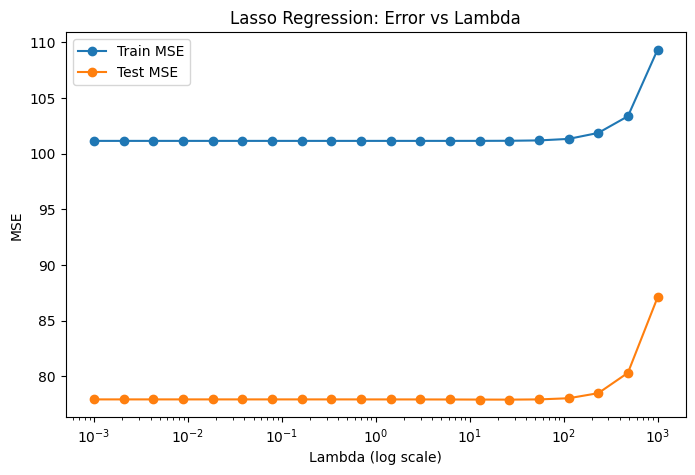

Best lambda for Lasso: 26.366508987303554
Train MSE at best lambda: 101.1478650016694
Test MSE at best lambda: 77.89856568255678
Number of near-zero weights at best lambda: 0


In [35]:
#TODO

lambdas_lasso = np.logspace(-3, 3, 20)
train_errors_lasso = []
test_errors_lasso = []

for lam in lambdas_lasso:
    lasso_model = LinearRegression(lr=0.1, n_iters=2000, penalty='l1', lambda_=lam)
    lasso_model.fit(X_fit, y_fit)
    train_pred = lasso_model.predict(X_fit)
    test_pred = lasso_model.predict(X_val)
    train_errors_lasso.append(mse(y_fit, train_pred))
    test_errors_lasso.append(mse(y_val, test_pred))

plt.figure(figsize=(8, 5))
plt.plot(lambdas_lasso, train_errors_lasso, marker='o', label='Train MSE')
plt.plot(lambdas_lasso, test_errors_lasso, marker='o', label='Test MSE')
plt.xscale('log')
plt.xlabel('Lambda (log scale)')
plt.ylabel('MSE')
plt.title('Lasso Regression: Error vs Lambda')
plt.legend()
plt.show()

best_lambda_lasso = lambdas_lasso[np.argmin(test_errors_lasso)]
print('Best lambda for Lasso:', best_lambda_lasso)

best_lasso_model = LinearRegression(lr=0.1, n_iters=2000, penalty='l1', lambda_=best_lambda_lasso)
best_lasso_model.fit(X_fit, y_fit)
print('Train MSE at best lambda:', mse(y_fit, best_lasso_model.predict(X_fit)))
print('Test MSE at best lambda:', mse(y_val, best_lasso_model.predict(X_val)))
print('Number of near-zero weights at best lambda:', int(np.sum(np.abs(best_lasso_model.weights) < 1e-3)))

<hr>
<hr>

# Problem 2 : Discriminant Analysis and Generative Modeling

## 2.1 - Introduction
In this assignment, you will implement Linear Discriminant Analysis (LDA) and Quadratic Discriminant Analysis (QDA) from scratch. We will explore the generative nature of these models and analyze their robustness to noise. By the end of this assignment, you will be able to quantify the performance degradation caused by noisy data and understand the theoretical differences between these classical approaches.

### Import Libraries

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Data Loading and Visualization 
Load the provided discriminant_data.csv. Visualize the distribution to identify the three classes.

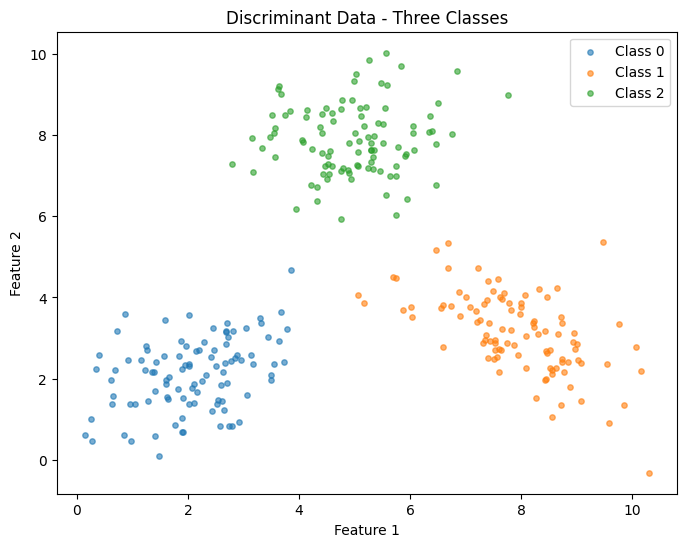

In [37]:
# Load the dataset
dataset = pd.read_csv('discriminant_data.csv')
# TODO
X_disc = dataset.iloc[:, :-1].values
y_disc = dataset.iloc[:, -1].values.astype(int)

plt.figure(figsize=(8, 6))
for c in np.unique(y_disc):
    plt.scatter(X_disc[y_disc == c, 0], X_disc[y_disc == c, 1],label=f'Class {c}', alpha=0.6, s=15)
    
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Discriminant Data - Three Classes')
plt.legend()
plt.show()

<hr>

## 2.2 - Discriminant Analysis Implementation
Implement the fit and predict functions for both LDA and QDA.

### LDA

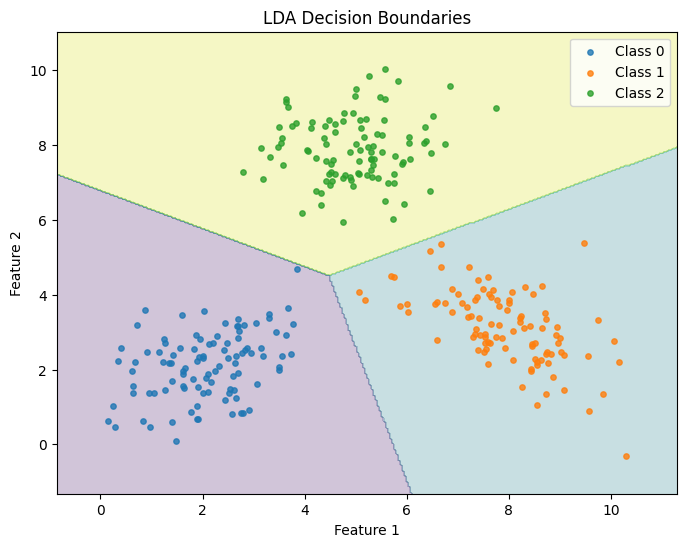

In [ ]:
def fit_lda(X, y):
    # TODO
    classes = np.unique(y)
    n_samples, n_features = X.shape
    means = {}
    priors = {}
    cov_pooled = np.zeros((n_features, n_features))

    for c in classes:
        X_c = X[y == c]
        means[c] = X_c.mean(axis=0)
        priors[c] = X_c.shape[0] / n_samples
        diff = X_c - means[c]
        cov_pooled += diff.T @ diff

    cov_pooled /= (n_samples - len(classes))

    return means, cov_pooled, priors

def predict_lda(X_test, means, cov, priors):
    # TODO
    cov_inv = np.linalg.inv(cov)
    scores = []
    for c in means:
        mean_c = means[c]
        w = cov_inv @ mean_c
        b = -0.5 * mean_c @ cov_inv @ mean_c + np.log(priors[c])
        score_c = X_test @ w + b
        scores.append(score_c)
    
    return np.argmax(np.array(scores), axis=0)


# Visualization code for decision boundaries
# TODO
def plot_decision_boundary(X, y, predict_fn, title, *args):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = predict_fn(grid, *args).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap='viridis')
    for c in np.unique(y):
        plt.scatter(X[y == c, 0], X[y == c, 1], label=f'Class {c}', s=15, alpha=0.8)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title(title)
    plt.legend()
    plt.show()


means_lda, cov_lda, priors_lda = fit_lda(X_disc, y_disc)
plot_decision_boundary(X_disc, y_disc, predict_lda, 'LDA Decision Boundaries', means_lda, cov_lda, priors_lda)

### QDA

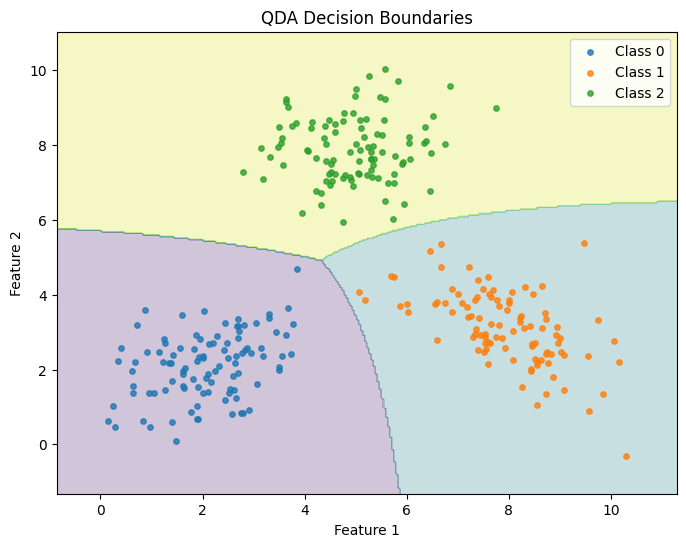

In [39]:
def fit_qda(X, y):
    # TODO
    classes = np.unique(y)
    means = {}
    covs = {}
    priors = {}
    n_samples = X.shape[0]

    for c in classes:
        X_c = X[y == c]
        means[c] = X_c.mean(axis=0)
        priors[c] = X_c.shape[0] / n_samples
        diff = X_c - means[c]
        covs[c] = (diff.T @ diff) / (X_c.shape[0] - 1)

    return means, covs, priors

def predict_qda(X_test, means, covs, priors):
    # TODO
    scores = []
    for c in means:
        mean_c = means[c]
        cov_c = covs[c]
        cov_inv = np.linalg.inv(cov_c)
        _, log_det = np.linalg.slogdet(cov_c)
        diff = X_test - mean_c
        quad_term = -0.5 * np.einsum('ij,jk,ik->i', diff, cov_inv, diff)
        score_c = quad_term - 0.5 * log_det + np.log(priors[c])
        scores.append(score_c)
    return np.argmax(np.array(scores), axis=0)

# Visualization
# TODO
means_qda, covs_qda, priors_qda = fit_qda(X_disc, y_disc)
plot_decision_boundary(X_disc, y_disc, predict_qda, 'QDA Decision Boundaries',means_qda, covs_qda, priors_qda)

<hr>

##  2.3 - Robustness to Noise
A robust model should handle outliers effectively. We will test how your models handle sensor noise (random outliers).
Implement the function below to inject noise into the dataset. Use np.random.seed(42) to ensure consistency for grading.

In [40]:
def add_noise(X, y, seed=42):
    # TODO: Implement noise injection
    # Inject 50 outliers distributed uniformly within the bounds of the original data
    # Ensure they are assigned random class labels (0, 1, or 2)
    rng = np.random.RandomState(seed)
    n_outliers = 50

    x_min, x_max = X[:, 0].min(), X[:, 0].max()
    y_min, y_max = X[:, 1].min(), X[:, 1].max()

    outliers_x = rng.uniform(x_min, x_max, size=n_outliers)
    outliers_y = rng.uniform(y_min, y_max, size=n_outliers)
    outliers = np.column_stack([outliers_x, outliers_y])

    outlier_labels = rng.randint(0, 3, size=n_outliers)

    X_noisy = np.vstack([X, outliers])
    y_noisy = np.concatenate([y, outlier_labels])

    return X_noisy, y_noisy

Re-train your LDA and QDA models on the noisy dataset and visualize the new boundaries. Observe how the decision regions warp in response to the outliers.

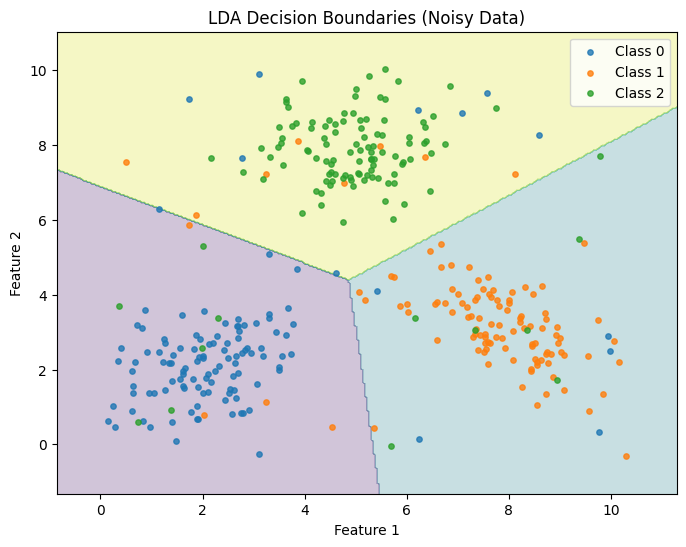

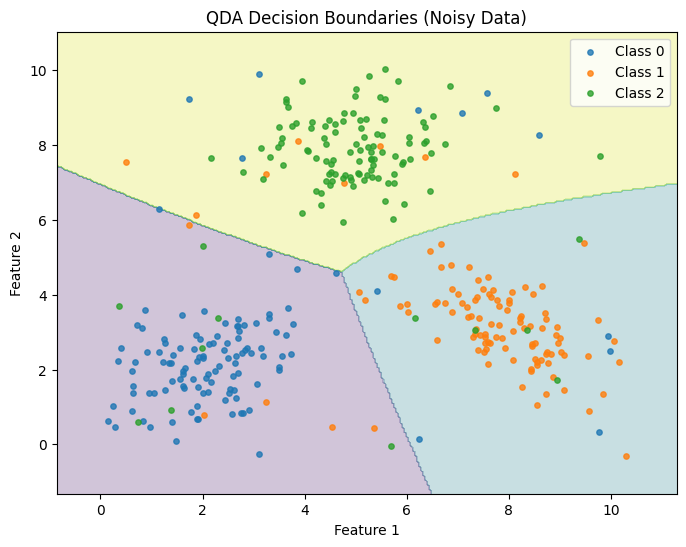

In [41]:
# TODO
X_noisy, y_noisy = add_noise(X_disc, y_disc, seed=42)

means_lda_n, cov_lda_n, priors_lda_n = fit_lda(X_noisy, y_noisy)
plot_decision_boundary(X_noisy, y_noisy, predict_lda,'LDA Decision Boundaries (Noisy Data)', means_lda_n, cov_lda_n, priors_lda_n)

means_qda_n, covs_qda_n, priors_qda_n = fit_qda(X_noisy, y_noisy)
plot_decision_boundary(X_noisy, y_noisy, predict_qda,'QDA Decision Boundaries (Noisy Data)', means_qda_n, covs_qda_n, priors_qda_n)

<hr>

##  2.4 - Generative Modeling
Since these models are generative, we can treat them as a probability distribution. Use your fitted parameters ($\mu_k$ and $\Sigma_k$) to generate synthetic data points.

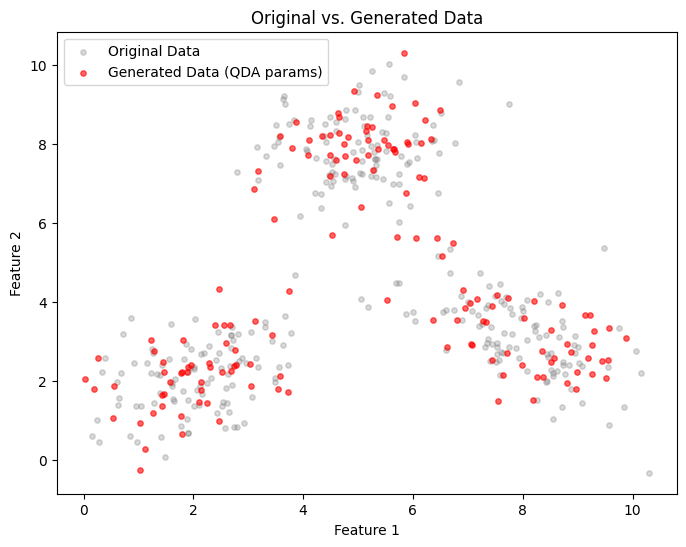

In [43]:
def generate_data(means, covs, n_samples_per_class=10):
    # TODO
    rng = np.random.RandomState(0)
    generated_data = []
    for c in means:
        mean_c = means[c]
        cov_c = covs[c]
        samples = rng.multivariate_normal(mean_c, cov_c, size=n_samples_per_class)
        generated_data.append(samples)
    return np.vstack(generated_data)

# Plotting original vs generated
# TODO
generated_qda = generate_data(means_qda, covs_qda, n_samples_per_class=50)

plt.figure(figsize=(8, 6))
plt.scatter(X_disc[:, 0], X_disc[:, 1], alpha=0.3, s=15, color='gray', label='Original Data')
plt.scatter(generated_qda[:, 0], generated_qda[:, 1], alpha=0.6, s=15, color='red', label='Generated Data (QDA params)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Original vs. Generated Data')
plt.legend()
plt.show()

<hr>

##  2.5 - Quantitative Evaluation of Generative Models
Unlike discriminative models where we rely on metrics like accuracy or precision to judge decision boundaries, generative models are evaluated based on their ability to capture the underlying probability distribution of the data. While visual inspection allows us to check for "plausibility," we require mathematical metrics to rigorously quantify "fidelity."

We will use two key methods to evaluate how well our model's generated distribution $Q$ matches the true distribution of the original data $P$:

### - Information Theoretic Metric: KL Divergence

The Kullback-Leibler (KL) Divergence measures the information lost when we approximate the true distribution $P$ with our model's distribution $Q$. It is defined as:


$$D_{KL}(P || Q) = \sum_{x \in \mathcal{X}} P(x) \ln \left( \frac{P(x)}{Q(x)} \right)$$


In our implementation, since the data is continuous, we approximate this by discretizing the feature space into a 2D grid (bins) and computing the relative frequencies.

### - Statistical Moment Matching

Since our discriminant analysis models assume Gaussian distributions, we can evaluate the model by comparing the first two moments (Mean and Covariance) of the original data ($P$) vs. the generated samples ($Q$):

* **Mean Error:** $\|\mu_{original} - \mu_{generated}\|$
* **Covariance Error:** $\|\Sigma_{original} - \Sigma_{generated}\|$


In [49]:
def calculate_kl_divergence(original, generated, bins=50, margin=0.5):
    # TODO
    x_min, x_max = original[:, 0].min() - margin, original[:, 0].max() + margin
    y_min, y_max = original[:, 1].min() - margin, original[:, 1].max() + margin
    bin_range = [[x_min, x_max], [y_min, y_max]]

    p_hist, _, _ = np.histogram2d(original[:, 0], original[:, 1], bins=bins, range=bin_range)
    q_hist, _, _ = np.histogram2d(generated[:, 0], generated[:, 1], bins=bins, range=bin_range)

    eps = 1e-10
    p = p_hist / p_hist.sum() + eps
    q = q_hist / q_hist.sum() + eps
    p = p / p.sum()
    q = q / q.sum()

    return np.sum(p * np.log(p / q))

def compare_statistics(original, generated):
    # TODO
    mu_original = original.mean(axis=0)
    mu_generated = generated.mean(axis=0)
    cov_original = np.cov(original, rowvar=False)
    cov_generated = np.cov(generated, rowvar=False)

    mu_diff = np.linalg.norm(mu_original - mu_generated)
    cov_diff = np.linalg.norm(cov_original - cov_generated)

    return mu_diff, cov_diff

Generate samples using the parameters obtained from your model trained on the original dataset. Use the functions above to report the KL Divergence and statistical errors.

Repeat the process using the parameters obtained from your model trained on the noisy dataset (from Section 4).

Compare your metrics for the "Clean" vs. "Noisy" experiments.

In [51]:
# TODO

generated_clean = generate_data(means_qda, covs_qda, n_samples_per_class=500)
kl_clean = calculate_kl_divergence(X_disc, generated_clean, bins=50)
mu_diff_clean, cov_diff_clean = compare_statistics(X_disc, generated_clean)

generated_noisy = generate_data(means_qda_n, covs_qda_n, n_samples_per_class=500)
kl_noisy = calculate_kl_divergence(X_disc, generated_noisy, bins=50)
mu_diff_noisy, cov_diff_noisy = compare_statistics(X_disc, generated_noisy)

print('Clean Data')
print('KL Divergence:', kl_clean)
print('Mean Error:', mu_diff_clean)
print('Covariance Error:', cov_diff_clean)
print()
print('Noisy Data')
print('KL Divergence:', kl_noisy)
print('Mean Error:', mu_diff_noisy)
print('Covariance Error:', cov_diff_noisy)

Clean Data
KL Divergence: 4.550787299843438
Mean Error: 0.04557525783367018
Covariance Error: 0.23458058958265468

Noisy Data
KL Divergence: 6.858798610849158
Mean Error: 0.055615979125318044
Covariance Error: 0.43492230317928415


Does the inclusion of noise increase the KL Divergence? Based on the Mean and Covariance error metrics, which parameter ($\mu$ or $\Sigma$) is more heavily distorted by the presence of outliers? Explain why this happens given the mathematical definition of Mean and Covariance.

Yes — adding the 50 outliers increases the KL Divergence between the true data distribution and the generated distribution, because the fitted Gaussian parameters no longer match the clean data as closely.

Between the two parameters, the **covariance** $\Sigma$ is typically distorted far more than the mean $\mu$. This follows directly from their mathematical definitions:

- The mean is $\mu = \frac{1}{n}\sum_i x_i$: each outlier contributes an additive, *linear* term. With only 50 outliers added to a much larger clean sample, their effect on the average is diluted roughly in proportion to $n_{outliers}/n_{total}$.
- The covariance is $\Sigma = \frac{1}{n}\sum_i (x_i-\mu)(x_i-\mu)^T$: each point's contribution involves a **squared** deviation from the mean. Outliers, by construction, lie far from the mean, so their $(x_i - \mu)(x_i-\mu)^T$ term is disproportionately large and dominates the sum even though there are few of them.


<hr>

## 2.6 - Theorical Questions

### Q1. LDA vs. QDA:
**Explain the mathematical assumption that makes LDA boundaries linear and QDA boundaries quadratic. Under what specific conditions would you expect LDA to outperform QDA, and vice-versa?**

LDA assumes that all classes share the *same* covariance matrix. When we write out the log-ratio of two classes' Gaussian densities, the quadratic terms $x^T \Sigma^{-1} x$ are identical for every class and cancel out, leaving only terms linear in $x$ hence a linear decision boundary. QDA allows each class to have its own covariance matrix $\Sigma_k$, so the quadratic terms $x^T \Sigma_k^{-1} x$ no longer cancel between classes, leaving a quadratic decision boundary.

LDA tends to outperform QDA when the classes truly share similar covariance structure or when training data is limited, since QDA has to estimate a separate covariance matrix per class (many more parameters), which increases variance and risk of overfitting with small samples. QDA tends to outperform LDA when the classes have different covariance structures (different shapes or orientations of their distributions) and there is enough data per class to estimate each covariance matrix reliably.

---

### Q2. Robustness and Noise:
**Based on your plots from Section 4, which model (LDA or QDA) was more affected by the injected noise? Provide a mathematical intuition for your observation based on how these models calculate their covariance matrices.**

QDA is more affected by injected outlier noise than LDA. QDA estimates a separate covariance matrix for each class from only that class's data, so outliers assigned to a given class can distort that one class's covariance estimate (and hence its decision region) without being diluted by the other classes' data. LDA pools all the data together into a single shared covariance matrix, so the same number of outliers, when spread across classes, gets averaged into one larger combined estimate, diluting their individual influence. Practically, this means QDA boundaries warp more around the outliers, while LDA boundaries shift more mildly and globally.

---

### Q3. Generative Modeling:
**Explain the "generative" intuition behind Discriminant Analysis. Why is it called a "Generative Model" instead of a "Discriminative Model"?**

Discriminant Analysis is called a "generative" model because it models the full joint distribution $p(x, y) = p(x \mid y) p(y)$, i.e. it explicitly models how the *features* are generated given the class as well as the class prior $p(y)$. Because it has access to $p(x \mid y)$, it can be used to generate new synthetic feature vectors for each class (as done in Section 2.4). A discriminative model, in contrast, only models the conditional $p(y \mid x)$ (or even just learns a direct decision boundary) and has no mechanism for generating new $x$ values.

---

### Q4. Metrics:
**KL Divergence: We used KL Divergence to measure the discrepancy between the original data distribution $P$ and our generated distribution $Q$. Mathematically, explain why $D_{KL}(P || Q)$ is not a true "distance" (i.e., why it is not symmetric). What does a high KL Divergence tell us about the quality of our generative parameters?**

 **Why is comparing the first moment (Mean) and the second moment (Covariance) a sufficient way to evaluate our model's performance? Hint: Relate your answer to the functional form of the Multivariate Normal Distribution:$$f(x) = \frac{1}{\sqrt{(2\pi)^k |\Sigma|}} \exp\left(-\frac{1}{2}(x-\mu)^T \Sigma^{-1} (x-\mu)\right)$$**

KL Divergence is not a true distance metric because it is not symmetric: $D_{KL}(P \| Q) \neq D_{KL}(Q \| P)$ in general. Intuitively, $D_{KL}(P \| Q)$ heavily penalizes regions where $P$ assigns high probability but $Q$ assigns low probability (because $\ln(P/Q) \to \infty$ there), while it doesn't symmetrically penalize regions where $Q$ has high probability but $P$ has low probability. A true distance would need to satisfy symmetry (and the triangle inequality), which KL divergence does not. A high KL Divergence tells us that the generated distribution $Q$ is a poor approximation of the true data distribution $P$ and that there are regions of meaningful probability mass under the true data that the generative model fails to reproduce well.

Comparing only the first two moments (mean and covariance) is sufficient to characterize a Multivariate Normal distribution, because, as the density formula shows, $f(x)$ depends on $x$ *only* through $\mu$ and $\Sigma$ and there are no other free parameters. Two Gaussians with identical mean and covariance are exactly the same distribution. So if our generative model assumes Gaussian class-conditionals as LDA/QDA do, matching the empirical mean and covariance of the generated samples to those of the real data is both a necessary and sufficient check of how well the model's distributional assumption has been satisfied.

<hr>
<hr>

# Problem 3: Some Minor Questions...

### Problem 3.1: Heteroskedastic Regression

Standard linear regression assumes constant variance. Given a dataset $\{x, y\}$ where the spread changes with the input (heteroskedasticity):  
- Explore: Plot the data to identify the non-linear mean trend and the input-dependent variance.
- Model: Propose functional forms for $\mu(x)$ and $\sigma^2(x)$ to formulate the full conditionally Gaussian model $p(y|x)$.  
- Estimate: Use Weighted Least Squares (WLS) to calculate the optimal parameters for your mean function.

Find the datapoints in the `heteroskedastic_data.csv`

          x           y
0  4.370861   45.449505
1  9.556429  214.544901
2  7.587945  130.971479
3  6.387926   81.083379
4  2.404168   13.320136


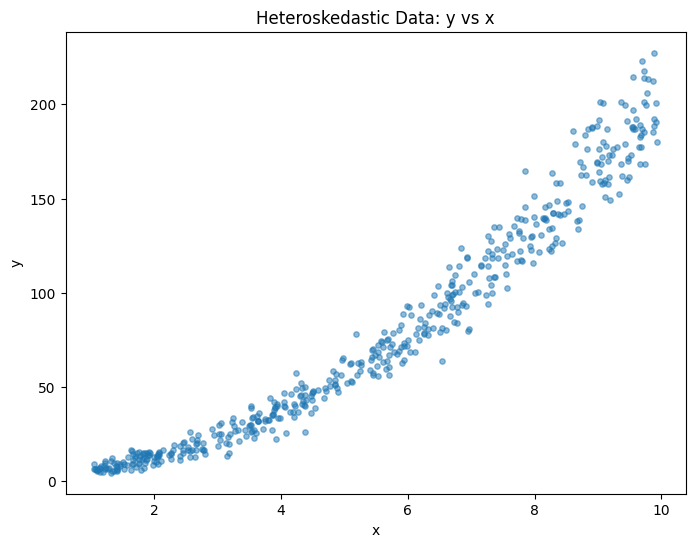

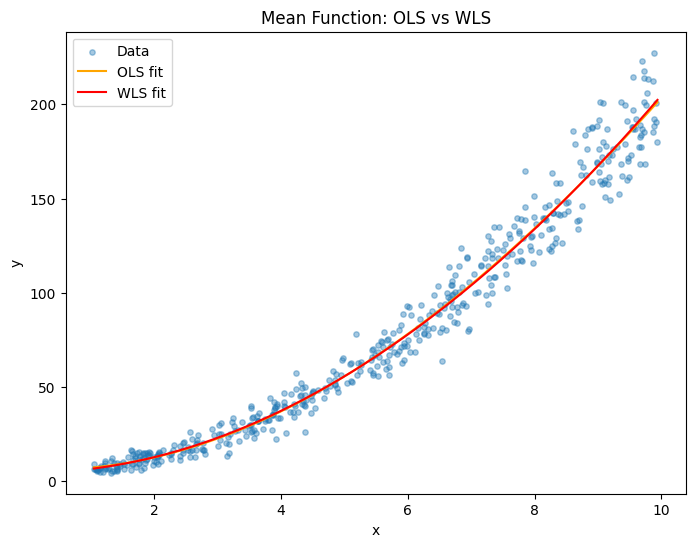

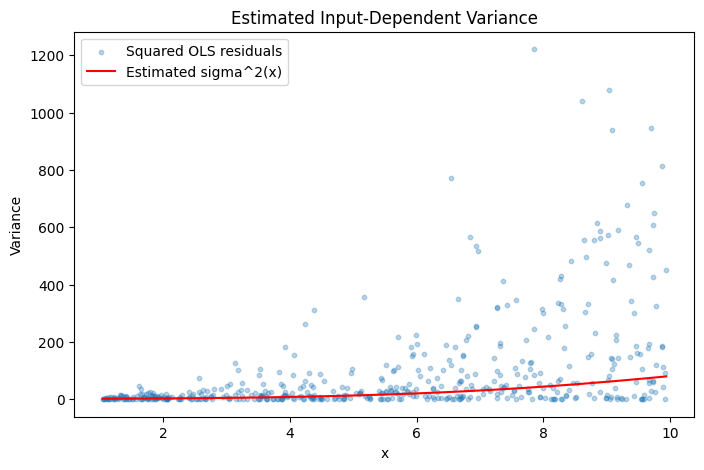

OLS coefficients (mu(x)): [ 6.4818773  -1.87005168  2.51887997 -0.03615077]
WLS coefficients (mu(x)): [ 4.31889158  0.02893466  2.08790724 -0.00854128]
Variance-model coefficients (log sigma^2(x)): [-0.28264381  0.67048339 -0.02028598]


In [ ]:
# Problem 3.1

data_hsk = pd.read_csv('heteroskedastic_data.csv')
print(data_hsk.head())

x_hsk = data_hsk.iloc[:, 0].values
y_hsk = data_hsk.iloc[:, 1].values

plt.figure(figsize=(8, 6))
plt.scatter(x_hsk, y_hsk, alpha=0.5, s=15)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Heteroskedastic Data: y vs x')
plt.show()

degree_mean = 3
poly_features = np.vander(x_hsk, degree_mean + 1, increasing=True)

theta_ols, _, _, _ = np.linalg.lstsq(poly_features, y_hsk, rcond=None)
residuals = y_hsk - poly_features @ theta_ols

degree_var = 2
var_features = np.vander(x_hsk, degree_var + 1, increasing=True)
log_sq_resid = np.log(residuals ** 2 + 1e-8)
gamma, _, _, _ = np.linalg.lstsq(var_features, log_sq_resid, rcond=None)
sigma2_hat = np.exp(var_features @ gamma)


W = np.diag(1.0 / sigma2_hat)
theta_wls = np.linalg.inv(poly_features.T @ W @ poly_features) @ poly_features.T @ W @ y_hsk

sort_idx = np.argsort(x_hsk)
plt.figure(figsize=(8, 6))
plt.scatter(x_hsk, y_hsk, alpha=0.4, s=15, label='Data')
plt.plot(x_hsk[sort_idx], (poly_features @ theta_ols)[sort_idx], color='orange', label='OLS fit')
plt.plot(x_hsk[sort_idx], (poly_features @ theta_wls)[sort_idx], color='red', label='WLS fit')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Mean Function: OLS vs WLS')
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(x_hsk, residuals ** 2, alpha=0.3, s=10, label='Squared OLS residuals')
plt.plot(x_hsk[sort_idx], sigma2_hat[sort_idx], color='red', label='Estimated sigma^2(x)')
plt.xlabel('x')
plt.ylabel('Variance')
plt.title('Estimated Input-Dependent Variance')
plt.legend()
plt.show()

print('OLS coefficients (mu(x)):', theta_ols)
print('WLS coefficients (mu(x)):', theta_wls)
print('Variance-model coefficients (log sigma^2(x)):', gamma)

<hr>

### Problem 3.2: Overfitting and Weight Amplitude
Overfitting is often accompanied by an increase in the amplitude of learned weights. You are given a 50-feature dataset where the true underlying relationship is simpler than the available data suggests.  
- Train: Build OLS models using only the first 3, 10, 25, and 50 features.
- Measure: Calculate the test MSE and the L2-norm of the weight vector for each model.
- Analyze: Identify the overfitted models and explain the relationship between model complexity, test MSE, training MSE and weight magnitude.

**As the number of features grows beyond the true underlying complexity, we expect training MSE to keep decreasing (more capacity to fit noise), test MSE to eventually increase (overfitting), and the L2-norm of the weight vector to grow, since the model needs increasingly large coefficients to fit the noise.**

Datasets can be found in the folder `problem_3_2_dataset`

['X_test.csv', 'X_train.csv', 'y_test.csv', 'y_train.csv']
Features= 3 | Train MSE=0.2942 | Test MSE=0.2280 | ||w||_2=4.8536
Features=10 | Train MSE=0.2735 | Test MSE=0.2729 | ||w||_2=4.7687
Features=25 | Train MSE=0.1889 | Test MSE=0.3904 | ||w||_2=4.8173
Features=50 | Train MSE=0.0500 | Test MSE=1.2938 | ||w||_2=5.0975


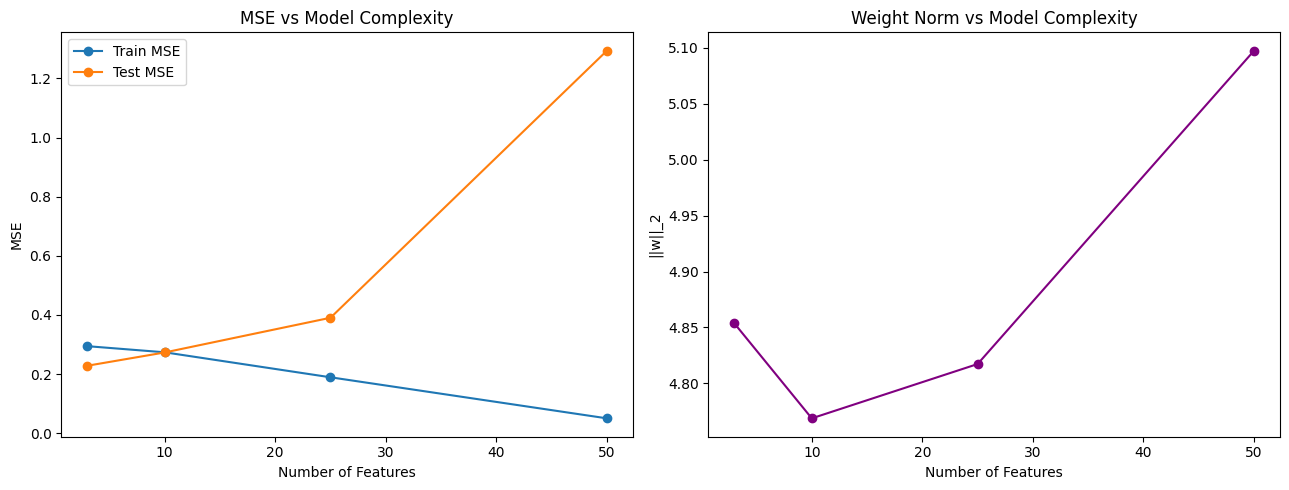

In [56]:
# Problem 3.2

import os

data_dir = 'problem_3_2_dataset'
print(os.listdir(data_dir))

X_train_p32 = pd.read_csv(os.path.join(data_dir, 'X_train.csv')).values
y_train_p32 = pd.read_csv(os.path.join(data_dir, 'y_train.csv')).values.flatten()
X_test_p32 = pd.read_csv(os.path.join(data_dir, 'X_test.csv')).values
y_test_p32 = pd.read_csv(os.path.join(data_dir, 'y_test.csv')).values.flatten()

feature_counts = [3, 10, 25, 50]
results = []

for k in feature_counts:
    Xtr_k = X_train_p32[:, :k]
    Xte_k = X_test_p32[:, :k]

    Xtr_b = np.concatenate([np.ones((Xtr_k.shape[0], 1)), Xtr_k], axis=1)
    Xte_b = np.concatenate([np.ones((Xte_k.shape[0], 1)), Xte_k], axis=1)

    theta_k, _, _, _ = np.linalg.lstsq(Xtr_b, y_train_p32, rcond=None)

    train_pred = Xtr_b @ theta_k
    test_pred = Xte_b @ theta_k

    train_mse_k = np.mean((y_train_p32 - train_pred) ** 2)
    test_mse_k = np.mean((y_test_p32 - test_pred) ** 2)
    weight_norm_k = np.linalg.norm(theta_k[1:]) 

    results.append((k, train_mse_k, test_mse_k, weight_norm_k))
    print(f'Features={k:2d} | Train MSE={train_mse_k:.4f} | Test MSE={test_mse_k:.4f} | 'f'||w||_2={weight_norm_k:.4f}')

results = np.array(results)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(results[:, 0], results[:, 1], marker='o', label='Train MSE')
axes[0].plot(results[:, 0], results[:, 2], marker='o', label='Test MSE')
axes[0].set_xlabel('Number of Features')
axes[0].set_ylabel('MSE')
axes[0].set_title('MSE vs Model Complexity')
axes[0].legend()

axes[1].plot(results[:, 0], results[:, 3], marker='o', color='purple')
axes[1].set_xlabel('Number of Features')
axes[1].set_ylabel('||w||_2')
axes[1].set_title('Weight Norm vs Model Complexity')

plt.tight_layout()
plt.show()


<hr>

### Problem 3.3: The Bayesian Inverse Problem
In many real-world systems, we observe undersampled, noisy measurements $y = Ax + e$. If the original signal $x$ is not sparse, standard recovery techniques fail. However, we often have historical data representing the prior distribution $P(x)$.
- Learn the Prior: Use the provided historical dataset to estimate the underlying distribution and covariance of $X$.
- Design the Cost Function: Formulate a differentiable cost function $J(x)$ that combines data fidelity (distance to $y$) with a penalty for low-probability states using your learned prior (e.g., using $-\log p(x)$ as a regularizer).
- Batch Reconstruction: You are provided with 20 new measurement vectors $y$. Optimize your cost function to recover the 20 corresponding $x$ vectors. Compute the average Mean Squared Error (MSE) across the batch to prove your method's effectiveness.

Datasets can be found in the folder `problem_3_3_dataset`

In [65]:
# Problem 3.3
import os

data_dir = 'problem_3_3_dataset'

X_hist = pd.read_csv(os.path.join(data_dir, 'X_historical.csv')).values
A = pd.read_csv(os.path.join(data_dir, 'A_matrix.csv'), header=None).values
Y_meas = pd.read_csv(os.path.join(data_dir, 'Y_measured_batch.csv'), header=None).values.T
X_true = pd.read_csv(os.path.join(data_dir, 'X_true_batch.csv')).values

mu_prior = X_hist.mean(axis=0)
cov_prior = np.cov(X_hist, rowvar=False)
cov_prior_inv = np.linalg.inv(cov_prior + 1e-6 * np.eye(cov_prior.shape[0]))

def cost_fn(x, y, A, mu_prior, cov_prior_inv, lam=1.0):
    data_term = np.sum((A @ x - y) ** 2)
    prior_term = (x - mu_prior) @ cov_prior_inv @ (x - mu_prior)
    return data_term + lam * prior_term

def reconstruct(y, A, mu_prior, cov_prior_inv, lam=1.0):
    lhs = A.T @ A + lam * cov_prior_inv
    rhs = A.T @ y + lam * (cov_prior_inv @ mu_prior)
    return np.linalg.solve(lhs, rhs)

n_signals = Y_meas.shape[0]
X_recovered = np.zeros((n_signals, mu_prior.shape[0]))

for i in range(n_signals):
    X_recovered[i] = reconstruct(Y_meas[i], A, mu_prior, cov_prior_inv, lam=1.0)

mse_batch = np.mean(np.sum((X_recovered - X_true) ** 2, axis=1))

X_no_prior = (Y_meas @ np.linalg.pinv(A).T) 
mse_no_prior = np.mean(np.sum((X_no_prior - X_true) ** 2, axis=1))

print('MSE without prior (pinv, underdetermined):', mse_no_prior)
print('MSE with prior:', mse_batch)

MSE without prior (pinv, underdetermined): 65.72827656306549
MSE with prior: 44.86268610669812
